<a href="https://colab.research.google.com/github/Nazarchona/Tutorial/blob/main/%D0%9B%D0%917_%D0%93%D1%83%D1%94%D0%B2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80_%D0%A4%D0%86%D0%A24_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [3]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# Перші рядки, структура й розмір датасету
display(df.head())
df.info()
print('Розмір датасету:', df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету: (2338, 14)


In [5]:
# Пропуски та дублікати
print('Пропуски за стовпцями:')
print(df.isnull().sum())
print('\nКількість дублікатів:', df.duplicated().sum())

Пропуски за стовпцями:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [6]:
# Описова статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
Датасет містить 2338 рядків і 14 стовпців: 13 числових ознак (інгредієнти) та цільову змінну Cured. Пропусків і дублікатів немає. Усі ознаки невід'ємні, у діапазоні приблизно від 1 до 45, мінімум у всіх ознак — 1.0. Середні значення різняться (від ~10.9 для Unicorn Horn і Minotaur Horn до ~16.9 для Troll Hair), стандартні відхилення — 7–9.6, тобто масштаби ознак близькі, але не однакові. Додаткове очищення не потрібне, стандартизація доцільна.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# Формуємо X (ознаки) та y (Cured)
X = df.drop(columns='Cured')
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_train:', X_train.shape, ' X_test:', X_test.shape)

X_train: (1870, 13)  X_test: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Кількість спостережень кожного класу в y_train
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

Cured
0    946
1    924
Name: count, dtype: int64
Cured
0    0.506
1    0.494
Name: proportion, dtype: float64


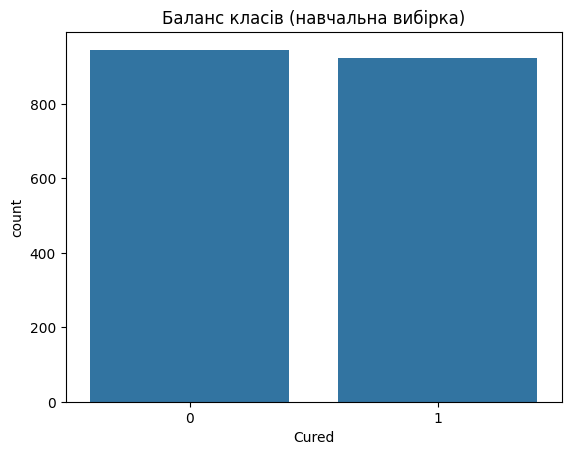

In [9]:
sns.countplot(x=y_train)
plt.title('Баланс класів (навчальна вибірка)')
plt.show()

**Висновок:**  
У навчальній вибірці 946 спостережень класу 0 (50.6%) і 924 класу 1 (49.4%), тобто класи практично збалансовані. Тому Accuracy тут є коректною метрикою. За сильного дисбалансу модель могла б мати високу Accuracy, просто передбачаючи переважаючий клас, і тоді треба було б дивитися на precision, recall та F1.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

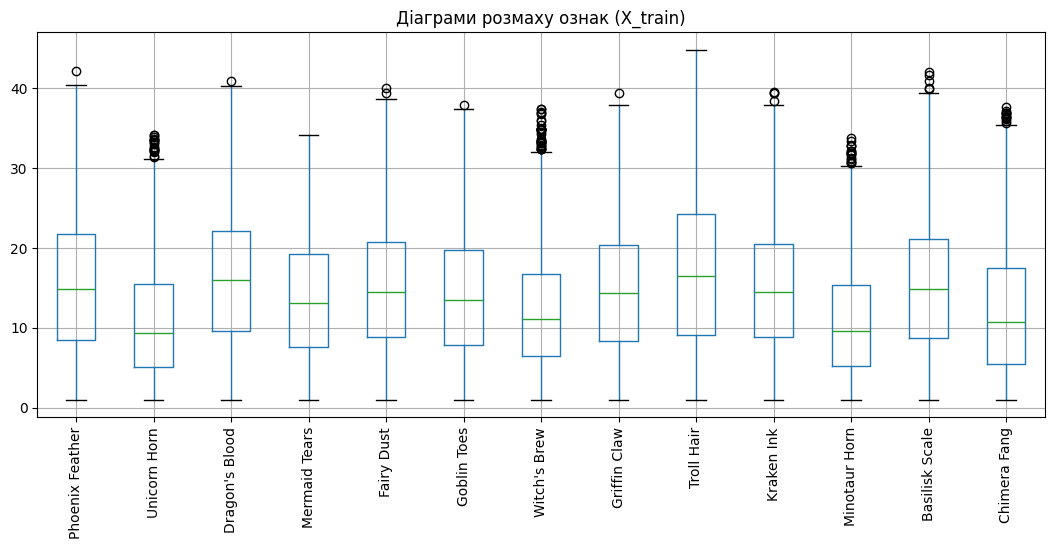

In [10]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху ознак (X_train)')
plt.show()

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
outliers.sort_values(ascending=False)

,0
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
За правилом 1.5·IQR найбільше потенційних викидів у ознаках Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) і Chimera Fang (13); в інших — від 0 до 5. Загалом це невелика частка від 1870 рядків. Розподіли ознак скошені вправо, тож «викиди» — це, ймовірно, природні великі значення, а не помилки. Автоматичне видалення зменшило б вибірку і могло б прибрати інформативні спостереження (наприклад, Witch's Brew пов'язаний із Cured), тому викиди залишено.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

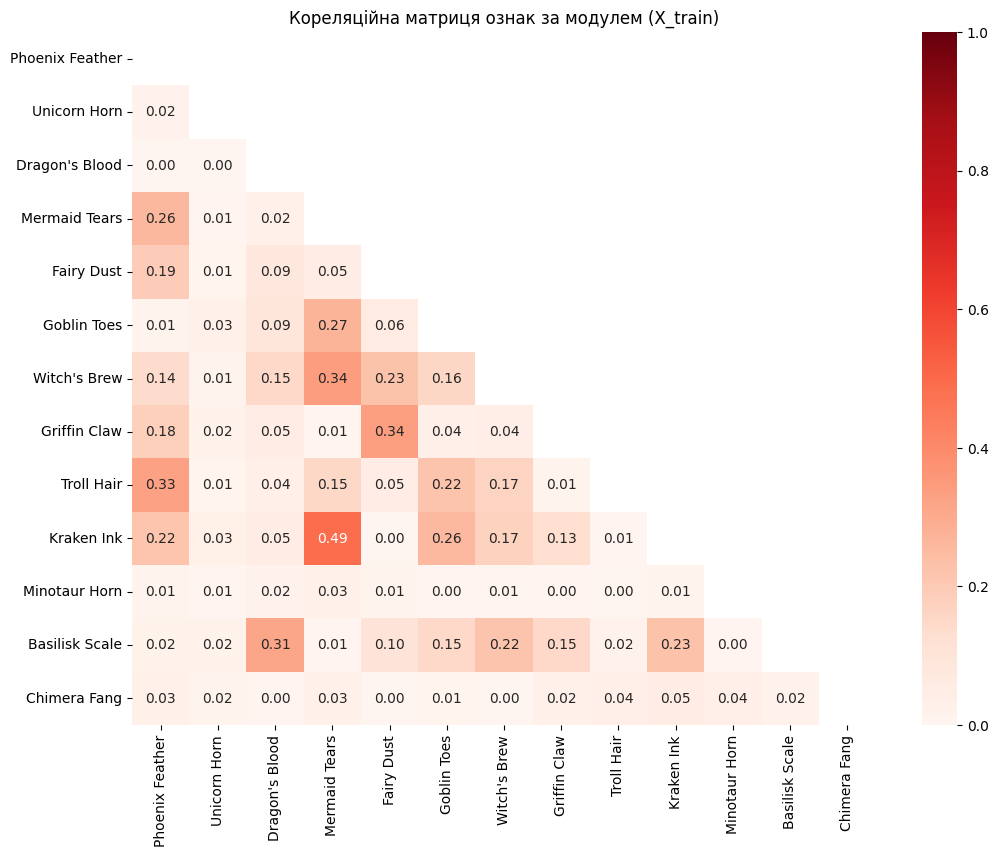

Kraken Ink      Mermaid Tears      0.490744
Witch's Brew    Mermaid Tears      0.343493
Griffin Claw    Fairy Dust         0.339391
Troll Hair      Phoenix Feather    0.330043
Basilisk Scale  Dragon's Blood     0.313266
Goblin Toes     Mermaid Tears      0.269868
Mermaid Tears   Phoenix Feather    0.259482
Kraken Ink      Goblin Toes        0.255796
Basilisk Scale  Kraken Ink         0.229592
Witch's Brew    Fairy Dust         0.226462
dtype: float64


In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Кореляційна матриця ознак за модулем (X_train)')
plt.show()

# Найбільш корельовані пари ознак
pairs = mtx.where(np.tril(np.ones(mtx.shape, dtype=bool), k=-1)).stack().sort_values(ascending=False)
print(pairs.head(10))

In [13]:
corr_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured')
corr_target.sort_values(key=abs, ascending=False)

,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
Найбільш корельовані пари ознак: Kraken Ink – Mermaid Tears (0.49), Witch's Brew – Mermaid Tears (0.34), Griffin Claw – Fairy Dust (0.34), Troll Hair – Phoenix Feather (0.33), Basilisk Scale – Dragon's Blood (0.31). Сильної мультиколінеарності (>0.7) немає. Найсильніший зв'язок із Cured мають Troll Hair (0.49) і Witch's Brew (0.25); решта ознак мають лінійну кореляцію з ціллю близьку до нуля (|r| < 0.06). Проте вони можуть впливати нелінійно або у взаємодії з іншими ознаками.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.mean(axis=0).round(3))
print(X_train_scaled.std(axis=0).round(3))

[ 0.  0.  0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

[[207  24]
 [ 26 211]]


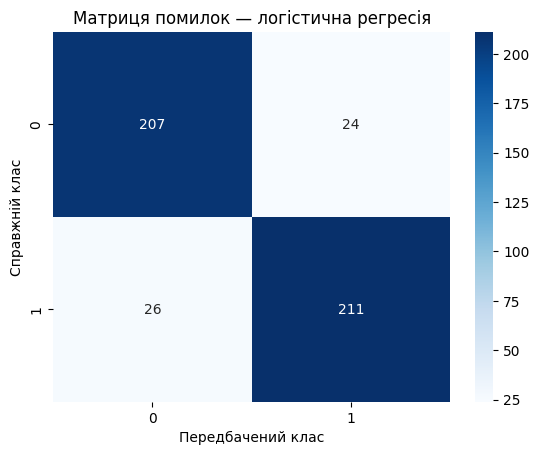

In [16]:
conf = confusion_matrix(y_test, y_pred)
print(conf)
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок — логістична регресія')
plt.show()

In [17]:
results = pd.DataFrame({'Справжній': y_test.values, 'Передбачений': y_pred}, index=y_test.index)
results.sample(10, random_state=42)

,Справжній,Передбачений
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
Базова логістична регресія дала Accuracy 0.893 на тестовій вибірці; precision, recall і F1 для обох класів ≈ 0.89–0.90. Матриця помилок: 207 TN, 24 FP, 26 FN, 211 TP. Помилки розподілені майже рівномірно: хибнонегативних (не вилікувано, хоча мало бути вилікувано) трохи більше (26 проти 24). Через збалансованість класів Accuracy тут інформативна, але однієї метрики замало: для задачі лікування важливо окремо контролювати recall класу 1 (не пропустити дієвий рецепт) та precision, тому варто дивитися також на F1 і матрицю помилок.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'newton-cg', 'saga'],
    'max_iter': [100, 500, 1000]
}
param_dist = {
    'C': np.logspace(-3, 3, 50),
    'solver': ['lbfgs', 'liblinear', 'newton-cg', 'saga'],
    'max_iter': [100, 200, 500, 1000, 2000]
}

In [19]:
grid = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)
print('GridSearchCV — найкращі параметри:', grid.best_params_)
print('GridSearchCV — найкраща CV accuracy:', round(grid.best_score_, 4))

GridSearchCV — найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
GridSearchCV — найкраща CV accuracy: 0.8674


In [20]:
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=30, cv=3,
                                   scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)
print('RandomizedSearchCV — найкращі параметри:', random_search.best_params_)
print('RandomizedSearchCV — найкраща CV accuracy:', round(random_search.best_score_, 4))

RandomizedSearchCV — найкращі параметри: {'solver': 'liblinear', 'max_iter': 2000, 'C': np.float64(25.595479226995334)}
RandomizedSearchCV — найкраща CV accuracy: 0.8674


In [21]:
best_search = grid if grid.best_score_ >= random_search.best_score_ else random_search
best_model = best_search.best_estimator_
print('Обрано:', 'GridSearchCV' if best_search is grid else 'RandomizedSearchCV', best_search.best_params_)
y_pred_best = best_model.predict(X_test_scaled)
print('Accuracy:', round(accuracy_score(y_test, y_pred_best), 4))
print(classification_report(y_test, y_pred_best))

Обрано: GridSearchCV {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
GridSearchCV обрав C=10, solver='lbfgs', max_iter=100; RandomizedSearchCV — C≈25.6, solver='liblinear', max_iter=2000. Обидва методи дали однакову найкращу CV-accuracy — 0.867. Обидва віддали перевагу слабшій регуляризації (більше C). Модель із GridSearchCV на тесті дала Accuracy 0.893 і F1 ≈ 0.89, тобто такий самий результат, як і базова модель. Підбір гіперпараметрів якість не покращив: лінійна межа рішень, а не налаштування регуляризації, обмежує логістичну регресію на цих даних.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
models = {
    'Logistic Regression': best_model,
    'SVC': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}
rows = []
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_test_scaled)
    rows.append({'Модель': name, 'Accuracy': accuracy_score(y_test, p), 'F1-score': f1_score(y_test, p)})
comparison = pd.DataFrame(rows).set_index('Модель').round(4).sort_values('F1-score', ascending=False)
display(comparison)
print('Найкраща модель:', comparison.index[0])

,Accuracy,F1-score
Модель,,
SVC,0.9594,0.9600
Logistic Regression,0.8932,0.8941
Decision Tree,0.8654,0.8657


Найкраща модель: SVC


### 13. Висновки до лабораторної роботи

1. **Особливості даних.** 2338 спостережень, 13 числових ознак і бінарна ціль Cured; пропусків і дублікатів немає; ознаки невід'ємні (1–45), зі скошеними вправо розподілами та дещо різними масштабами. Класи збалансовані (≈50.6% / 49.4%).
2. **Викиди й кореляції (на навчальній вибірці).** Потенційних викидів небагато, найбільше в Witch's Brew (33), Unicorn Horn (20) та Minotaur Horn (18); їх не видаляли, бо це, ймовірно, природні значення. Сильної мультиколінеарності немає (максимум 0.49 для Kraken Ink – Mermaid Tears). З ціллю найсильніше пов'язані Troll Hair (0.49) і Witch's Brew (0.25), інші ознаки лінійно майже не корелюють із Cured.
3. **Базова логістична регресія.** Accuracy 0.893, F1 ≈ 0.894; 24 FP і 26 FN — помилки збалансовані.
4. **Підбір гіперпараметрів.** GridSearchCV (C=10, lbfgs) і RandomizedSearchCV (C≈25.6, liblinear) дали CV-accuracy 0.867; на тесті якість лишилась тією ж (0.893), тобто покращення немає.
5. **Найкраща модель — SVC** (RBF-ядро): Accuracy 0.959, F1 0.960, проти 0.893 / 0.894 у логістичної регресії та 0.865 / 0.866 у дерева рішень. SVC з нелінійним ядром краще описує нелінійну залежність Cured від комбінацій інгредієнтів, тоді як логістична регресія обмежена лінійною межею, а одиночне дерево без обмеження глибини перенавчається.